In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import shapiro, levene, f_oneway
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from itertools import combinations
import sys


In [3]:
print(sys.version)


3.11.18 | packaged by Anaconda, Inc. | (main, Oct 26 2026, 18:13:29) [MSC v.1942 64 bit (AMD64)]


In [6]:
def plot_bars_with_sem3_test(groups, labels=None, ylabel="Value", figsize=(3,6),
                       bar_color="lightgray", dot_color="black", spine_width=2):
    """
    Plot multiple groups as bars with SEM and overlay individual data points.

    Parameters
    ----------
    groups : list of array-like
        List of numeric arrays/lists, one per group.
    labels : list of str, optional
        Labels for each group (x-axis).
    ylabel : str, optional
        Label for y-axis.
    figsize : tuple, optional
        (width, height) of the figure in inches.
    bar_color : str, optional
        Color of the bars.
    dot_color : str, optional
        Color of the overlaid dots.
    spine_width : float, optional
        Thickness of the axis spines.
    """

    groups = [np.asarray(g) for g in groups]
    n_groups = len(groups)

    # Allow single color or list of colors
    if isinstance(bar_color, (list, tuple, np.ndarray)):
        if len(bar_color) != n_groups:
            raise ValueError("Length of bar_color must match number of groups")
        bar_colors = bar_color
    else:
        bar_colors = [bar_color] * n_groups

    print(bar_colors)

    means = [np.nanmean(g) for g in groups]
    sems  = [np.nanstd(g, ddof=1) / np.sqrt(np.sum(~np.isnan(g))) for g in groups]


    if labels is None:
        labels = [f"Group {i+1}" for i in range(n_groups)]
    for i,lbl in enumerate(labels):
        print(f"group: {lbl}, mean: {means[i]}, sem: {sems[i]}")

    fig, ax = plt.subplots(figsize=figsize)
    x = np.arange(n_groups)

    # Bars + SEM
    ax.bar(x, means, yerr=sems, capsize=8,
           color=bar_colors, edgecolor="black", linewidth=1.5)

    # Overlay dots
    for i, vals in enumerate(groups):
        # jitter = (np.random.rand(len(vals)) - 0.5) * 0.2
        jitter = 0
        ax.scatter(np.full(len(vals), x[i]) + jitter, vals,
                   color=dot_color, s=40, alpha=0.8, zorder=3)

    # Axis labels & limits
    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    ax.set_ylabel(ylabel)
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")


    # --- Style adjustments ---
    # Thicker left & bottom spines, remove top/right
    for spine in ["left", "bottom"]:
        ax.spines[spine].set_linewidth(spine_width)
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)

    # Ticks only on left/bottom
    ax.yaxis.set_ticks_position("left")
    ax.xaxis.set_ticks_position("bottom")

    # Add baseline at y = 0
    ax.axhline(0, color="black", linewidth=1.2)

    plt.tight_layout()
    return ax

#def add_sig_bar(ax, x1, x2, y, h, text, fontsize=16):
#    ax.plot([x1, x1, x2, x2],
 #           [y, y+h, y+h, y],
  #          lw=1.5, color="black")
   # ax.text((x1+x2)/2, y+h, text,
    #        ha="center", va="bottom",
     #       fontsize=fontsize, fontweight="bold")

In [7]:


def shapiro_wilk(list_arrays, list_labels, alpha=0.05):
    """
    Run Shapiro-Wilk normality test on each group.
    Returns True only if ALL groups pass (p > alpha).
    """
    pass_normality = True  # start True, AND across all groups

    for name, group in zip(list_labels, list_arrays):
        stat, p = shapiro(group)

        print(f"{name}")
        print(f"  W statistic = {stat:.4f}")
        print(f"  p-value     = {p:.4f}")

        if p > alpha:
            print("  → Data look approximately normal\n")
        else:
            print("  → Significant deviation from normality\n")
            pass_normality = False  # any failure fails the whole check

    return pass_normality


def levene_and_brown_forsythe_test(list_arrays, test2run=0, alpha=0.05):
    test = [["Brown-Forsythe test", "median"], ["Levene's test", "mean"]]

    pass_similar_var = False
    if test2run < 2:
        test = [test[test2run]]

    for i in range(len(test)):
        stat, p_val = levene(*list_arrays, center=test[i][1])
        print(f'{test[i][0]}')
        print(f"Statistic = {stat:.4f}")
        print(f"p-value   = {p_val:.4f}")

        if p_val > alpha:
            print("→ Variances are not significantly different\n")
            if test2run < 2:
                pass_similar_var = True
        else:
            print("→ Variances differ significantly\n")

    return pass_similar_var


def anova_test(list_arrays, alpha=0.05):
    f_stat, p_value = f_oneway(*list_arrays)

    print("One-way ANOVA")
    print(f"F statistic = {f_stat:.4f}")
    print(f"p-value     = {p_value:.4f}")

    if p_value < alpha:
        print("→ Significant differences exist between groups\n")
        pass_anova = True
    else:
        print("→ No significant differences detected\n")
        pass_anova = False
    return pass_anova


def ETA_SQUARED(list_arrays):
    all_data = np.concatenate(list_arrays)
    grand_mean = np.mean(all_data)

    ss_between = sum(
        len(group) * (np.mean(group) - grand_mean) ** 2
        for group in list_arrays
    )
    ss_total = sum((x - grand_mean) ** 2 for x in all_data)

    eta_squared = ss_between / ss_total

    print("\nEffect size")
    print(f"Eta squared (η²) = {eta_squared:.4f}")

    if eta_squared < 0.01:
        interpretation = "very small"
    elif eta_squared < 0.06:
        interpretation = "small"
    elif eta_squared < 0.14:
        interpretation = "medium"
    else:
        interpretation = "large"

    print(f"Effect size interpretation: {interpretation}")
    return eta_squared


def tukey_test(list_arrays, list_labels):
    all_data = np.concatenate(list_arrays)
    labels = np.concatenate([
        np.repeat(name, len(group))
        for name, group in zip(list_labels, list_arrays)
    ])

    tukey = pairwise_tukeyhsd(endog=all_data, groups=labels, alpha=0.05)
    print(tukey)
    return tukey


def cohens_d(x, y):
    nx = len(x)
    ny = len(y)
    pooled_sd = np.sqrt(
        ((nx - 1) * np.var(x, ddof=1) + (ny - 1) * np.var(y, ddof=1))
        / (nx + ny - 2)
    )
    d = (np.mean(x) - np.mean(y)) / pooled_sd
    return d


def cohens_all(list_arrays, list_labels):
    print("\nCohen's d pairwise comparisons")  # was dead code after `return` before
    for (i, g1), (j, g2) in combinations(enumerate(list_arrays), 2):
        d = cohens_d(g1, g2)

        print(f"{list_labels[i]} vs {list_labels[j]}")
        print(f"  Cohen's d = {d:.4f}")

        abs_d = abs(d)
        if abs_d < 0.2:
            size = "very small"
        elif abs_d < 0.5:
            size = "small"
        elif abs_d < 0.8:
            size = "medium"
        else:
            size = "large"

        print(f"  Effect size: {size}\n")


def fast_plotter(dates, bar_color="lightgray"):
    #sheet_url = "https://docs.google.com/spreadsheets/d/1YpXxk7YYIIJh5XcIkcv7oECVNmW58WHS_IbCw-qfRhc/export?format=csv&gid=1997495720"
    #sheet_url = "https://docs.google.com/spreadsheets/d/1YpXxk7YYIIJh5XcIkcv7oECVNmW58WHS_IbCw-qfRhc/export?format=csv&gid=1997495720"
    sheet_url = "https://docs.google.com/spreadsheets/d/1W7nivwtWDtfesls5BOMkxc-LNFCgb-9KKkpFHTYq8sk/export?format=csv&gid=387761554"

    vals_arrays = []
    df = pd.read_csv(sheet_url, decimal=",")

    for date in dates:
        vals = df[df["date"] == date].drop(columns=["date"])
        for col in vals.columns:
            vals[col] = pd.to_numeric(vals[col], errors="coerce")

        vals_array = vals.values.flatten()
        vals_array = vals_array[~np.isnan(vals_array)]

        print(date, vals_array, type(vals_array))
        vals_arrays.append(vals_array)

    # STATS ######################################
    print('\n---------- STATS ----------')
    pass_normality = shapiro_wilk(vals_arrays, dates)

    if len(dates) > 1:
        pass_similar_var = levene_and_brown_forsythe_test(vals_arrays)
    else:
        pass_similar_var = False

    pass_anova = False  # default so it's defined even if block below is skipped

    if pass_normality and pass_similar_var:
        pass_anova = anova_test(vals_arrays)
        ETA_SQUARED(vals_arrays)

        # Only run post-hoc pairwise tests if the omnibus ANOVA was significant
        if pass_anova:
            tukey_test(vals_arrays, dates)
            cohens_all(vals_arrays, dates)
        else:
            print("ANOVA not significant → skipping post-hoc Tukey/Cohen's d\n")

    # PLOT ######################################
    ax = plot_bars_with_sem3_test(
        vals_arrays,
        labels=dates,
        ylabel="Performance Index",
        bar_color=bar_color,
        figsize=(6, 6)
    )

   # add_sig_bar(ax, 0, 2, 0.04, 0.015, "*")
   # add_sig_bar(ax, 1, 2, 0.08, 0.015, "**")

    all_vals = np.concatenate(vals_arrays)
    ax.set_ylim(min(all_vals)- 0.1, max(all_vals) + 0.1)
    ax.tick_params(axis="both", labelsize=14)
    ax.yaxis.label.set_size(16)

    plt.show()

In [18]:
sheet_url = "https://docs.google.com/spreadsheets/d/1W7nivwtWDtfesls5BOMkxc-LNFCgb-9KKkpFHTYq8sk/export?format=csv&gid=387761554"

df= pd.read_csv(sheet_url, decimal=",")
print(df.columns.tolist())
print(df.head())
Dates = df["date"]
print(Dates)



['date', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6']
              date      Unnamed: 1      Unnamed: 2      Unnamed: 3  \
0       15/10/2026    0.1833333333  -0.08275862069    0.2272727273   
1       21/10/2026  -0.01725625539   -0.2144444444  -0.06711915535   
2       22/10/2026   -0.1066666667   -0.2098930481   -0.1235294118   
3     28/10/2026_T   -0.2456140351   -0.2727272727   -0.1911764706   
4  28/10/2026_MbyH   -0.1785714286           0.175   -0.2855855856   

         Unnamed: 4      Unnamed: 5      Unnamed: 6  
0    -0.05714285714    0.2076923077   0.07558139535  
1    -0.04910714286  0.009803921569   -0.3360215054  
2  -0.0005617977528   -0.3312909814  -0.05655655656  
3               NaN             NaN             NaN  
4               NaN             NaN             NaN  
0           15/10/2026
1           21/10/2026
2           22/10/2026
3         28/10/2026_T
4      28/10/2026_MbyH
5     28/10/2026_MbyAl
6         29/10/2026_T
7

15
15
15/10/2026 [ 0.18333333 -0.08275862  0.22727273 -0.05714286  0.20769231  0.0755814 ] <class 'numpy.ndarray'>
21/10/2026 [-0.01725626 -0.21444444 -0.06711916 -0.04910714  0.00980392 -0.33602151] <class 'numpy.ndarray'>
22/10/2026 [-0.10666667 -0.20989305 -0.12352941 -0.0005618  -0.33129098 -0.05655656] <class 'numpy.ndarray'>
28/10/2026_T [-0.24561404 -0.27272727 -0.19117647] <class 'numpy.ndarray'>
28/10/2026_MbyH [-0.17857143  0.175      -0.28558559] <class 'numpy.ndarray'>
28/10/2026_MbyAl [-0.3452381   0.21824687 -0.30355666] <class 'numpy.ndarray'>
29/10/2026_T [-0.39054054 -0.33333333 -0.34288086] <class 'numpy.ndarray'>
29/10/2026_MbyH [-0.07612179 -0.11129568 -0.14772727] <class 'numpy.ndarray'>
29/10/2026_MbyAl [-0.19134199 -0.13149351 -0.20952381] <class 'numpy.ndarray'>
04/11/2026_T [-0.39054054 -0.33333333 -0.34288086] <class 'numpy.ndarray'>
04/11/2026_MbyH [-0.28457447 -0.20126227 -0.14300203] <class 'numpy.ndarray'>
04/11/2026_MbyAl [-0.49206349  0.01449275 -0.48148

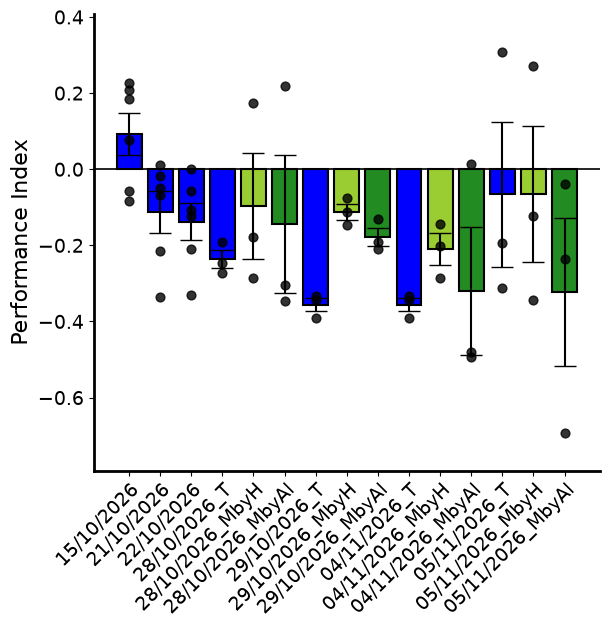

In [20]:
colors= ["blue", "blue", "blue", "blue", "yellowgreen", "forestgreen", "blue", "yellowgreen", "forestgreen", "blue", "yellowgreen", "forestgreen", "blue", "yellowgreen", "forestgreen"]
print(len(Dates))
print(len(colors))
fast_plotter(Dates, colors)